# Airline Customer Satisfaction Prediction
## Decision Tree Classification

This notebook adapts `decision_tree_airline.py` into an interactive, step-by-step Jupyter workflow.

**Objective:** predict airline passenger satisfaction using the `satisfaction` target column in `Invistico_Airline.csv`.

### Workflow
1. Load and inspect the dataset.
2. Identify numerical and categorical features.
3. Split the data into training and testing sets.
4. Build leakage-safe preprocessing and Decision Tree pipelines.
5. Tune hyperparameters with `GridSearchCV`.
6. Evaluate test-set performance.
7. Inspect feature importance and visualize the trained tree.

> Place `Invistico_Airline.csv` in the same folder as this notebook, or update `DATA_PATH` in the configuration cell.


## 1. Install dependencies

If the packages are not already installed in your Jupyter environment, run the following cell. You may need to restart the kernel after installation.


In [1]:
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries and configure the project

The target is `satisfaction`. The script automatically detects numerical and categorical predictor columns based on their pandas data types.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Update this path if your CSV is stored elsewhere.
DATA_PATH = Path("Invistico_Airline.csv")
TARGET = "satisfaction"
OUTPUT_DIR = Path("decision_tree_output")
RANDOM_STATE = 42

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 3. Load and inspect the dataset

Rows with a missing target value are removed because supervised learning requires a known label. Missing predictor values are handled later inside the preprocessing pipeline.


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place Invistico_Airline.csv beside this notebook or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.dropna(subset=[TARGET]).copy()

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset shape: 129,880 rows × 22 columns


,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,3,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,3,...,4,2,2,0,2,4,2,5,0,0.0


### 3.1 Target distribution and missing values

Reviewing class counts helps understand whether the target classes are balanced. The missing-value summary shows which input columns need imputation.


In [4]:
print("Target class counts:")
display(df[TARGET].value_counts().rename("count").to_frame())

print("Target class proportions:")
display(
    df[TARGET].value_counts(normalize=True)
      .mul(100)
      .round(2)
      .rename("percentage")
      .to_frame()
)

missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Columns with missing values:")
display(missing_values.rename("missing values").to_frame())


Target class counts:


,count
satisfaction,
satisfied,71087
dissatisfied,58793


Target class proportions:


,percentage
satisfaction,
satisfied,54.73
dissatisfied,45.27


Columns with missing values:


,missing values
Arrival Delay in Minutes,393


## 4. Separate features and target

The target column is excluded from the feature matrix. Numerical and categorical features are automatically identified.


In [5]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

# Treat any remaining, uncommon data types as categorical.
other_features = [
    column for column in X.columns
    if column not in numeric_features and column not in categorical_features
]
categorical_features.extend(other_features)

print(f"Numerical features ({len(numeric_features)}):")
print(numeric_features)

print(f"\nCategorical features ({len(categorical_features)}):")
print(categorical_features)


Numerical features (18):
['Age', 'Flight Distance', 'Seat comfort', 'Departure/Arrival time convenient', 'Food and drink', 'Gate location', 'Inflight wifi service', 'Inflight entertainment', 'Online support', 'Ease of Online booking', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Online boarding', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

Categorical features (3):
['Customer Type', 'Type of Travel', 'Class']


## 5. Split into training and testing sets

The 80/20 split reserves the test set for final evaluation. `stratify=y` keeps approximately the same target-class proportions in both subsets. The random state makes the split reproducible.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training records: {len(X_train):,}")
print(f"Testing records:  {len(X_test):,}")


Training records: 103,904
Testing records:  25,976


## 6. Build preprocessing pipelines

- Numerical columns: missing values are replaced with the **median**.
- Categorical columns: missing values are replaced with the **most frequent** value, then encoded using **OneHotEncoder**.
- `handle_unknown="ignore"` allows the pipeline to transform categories that were not seen during training.

Preprocessing is part of the model pipeline. Therefore, during cross-validation, imputers and encoders are fitted only on each fold's training data, helping prevent data leakage.


In [7]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

transformers = []

if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]
)

model_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

## 7. Hyperparameter tuning with GridSearchCV

A Decision Tree can overfit if it grows too complex. This grid tests different maximum depths and minimum leaf sizes.

The search uses 3-fold cross-validation and weighted F1-score. The test set is not used to select hyperparameters.


In [8]:
parameter_grid = {
    "classifier__max_depth": [3, 5, 8],
    "classifier__min_samples_leaf": [5, 10],
    "classifier__criterion": ["gini"],
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameter_grid,
    scoring="f1_weighted",
    cv=3,
    n_jobs=-1,
    verbose=1,
    refit=True,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)
print(f"\nBest mean cross-validation weighted F1: {grid_search.best_score_:.4f}")


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 5}

Best mean cross-validation weighted F1: 0.9124


### 7.1 Compare the tested configurations

The cross-validation results help show how the tested tree settings performed. The best configuration is selected using the weighted F1-score.


In [9]:
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            "param_classifier__max_depth",
            "param_classifier__min_samples_leaf",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ].sort_values("rank_test_score")
    .rename(columns={
        "param_classifier__max_depth": "max_depth",
        "param_classifier__min_samples_leaf": "min_samples_leaf",
        "mean_test_score": "mean_weighted_f1",
        "std_test_score": "std_weighted_f1",
        "rank_test_score": "rank",
    })
    .reset_index(drop=True)
)


,max_depth,min_samples_leaf,mean_weighted_f1,std_weighted_f1,rank
0,8,5,0.912442,0.002447,1
1,8,10,0.911899,0.002801,2
2,5,5,0.873480,0.003649,3
3,5,10,0.873479,0.003633,4
4,3,5,0.854667,0.002219,5
5,3,10,0.854667,0.002219,5


## 8. Evaluate on the test set

The selected model is evaluated on the held-out test data. Accuracy measures overall correctness; precision, recall, and F1-score provide class-level detail.


In [10]:
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Test accuracy: 0.9114

Classification report:
              precision    recall  f1-score   support

dissatisfied       0.91      0.90      0.90     11759
   satisfied       0.91      0.92      0.92     14217

    accuracy                           0.91     25976
   macro avg       0.91      0.91      0.91     25976
weighted avg       0.91      0.91      0.91     25976



### 8.1 Confusion matrix

Rows represent actual classes and columns represent predicted classes. The diagonal cells contain correct predictions; off-diagonal cells contain errors.


,Predicted: dissatisfied,Predicted: satisfied
Actual: dissatisfied,10531,1228
Actual: satisfied,1074,13143


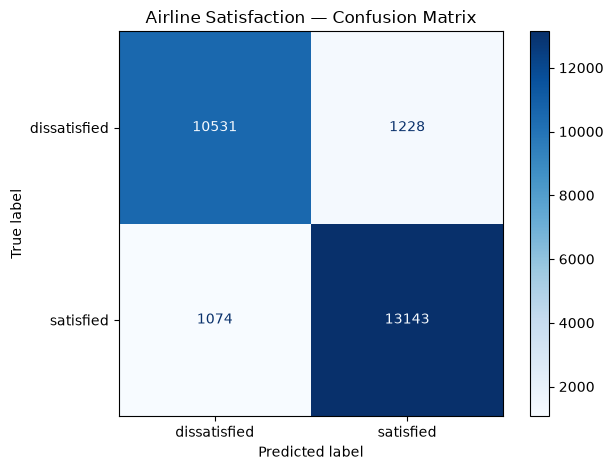

In [11]:
classes = best_model.named_steps["classifier"].classes_

cm = confusion_matrix(y_test, y_pred, labels=classes)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in classes],
    columns=[f"Predicted: {label}" for label in classes],
)

display(cm_df)

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes,
)

confusion_display.plot(cmap="Blues", values_format="d")
plt.title("Airline Satisfaction — Confusion Matrix")
plt.tight_layout()

confusion_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(confusion_path, dpi=200, bbox_inches="tight")
plt.show()


## 9. Feature importance

The tree exposes an importance score for each transformed input feature. Since categorical variables are one-hot encoded, one original categorical column can produce several transformed feature names.

Importance scores describe how the fitted tree used features for splitting; they do not prove that a feature causes satisfaction.


In [12]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_tree = best_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

feature_importances = pd.Series(
    fitted_tree.feature_importances_,
    index=feature_names,
    name="importance",
).sort_values(ascending=False)

print("Top 20 feature importances:")
display(feature_importances.head(20).to_frame())

importance_path = OUTPUT_DIR / "feature_importances.csv"
feature_importances.to_csv(importance_path, header=True)


Top 20 feature importances:


,importance
numeric__Inflight entertainment,0.516992
numeric__Seat comfort,0.214041
numeric__Ease of Online booking,0.079661
categorical__Customer Type_Loyal Customer,0.029030
categorical__Class_Business,0.023352
numeric__Gate location,0.020042
categorical__Customer Type_disloyal Customer,0.016826
numeric__Online support,0.014112
categorical__Type of Travel_Business travel,0.012781
numeric__Leg room service,0.011823


### 9.1 Plot the most important features


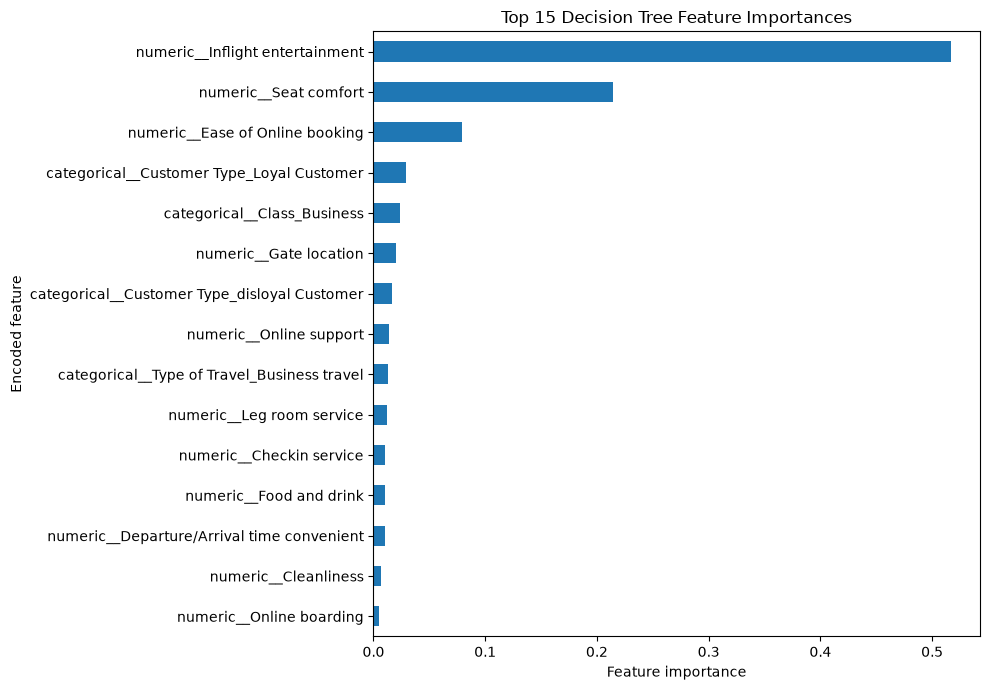

In [13]:
top_n = 15
top_importances = feature_importances.head(top_n).sort_values()

plt.figure(figsize=(10, 7))
top_importances.plot(kind="barh")
plt.xlabel("Feature importance")
plt.ylabel("Encoded feature")
plt.title(f"Top {top_n} Decision Tree Feature Importances")
plt.tight_layout()
plt.show()


## 10. Visualize the trained Decision Tree

The visualization below displays only the first three levels so the diagram remains readable. This is a display limit only; it does not change the fitted model.


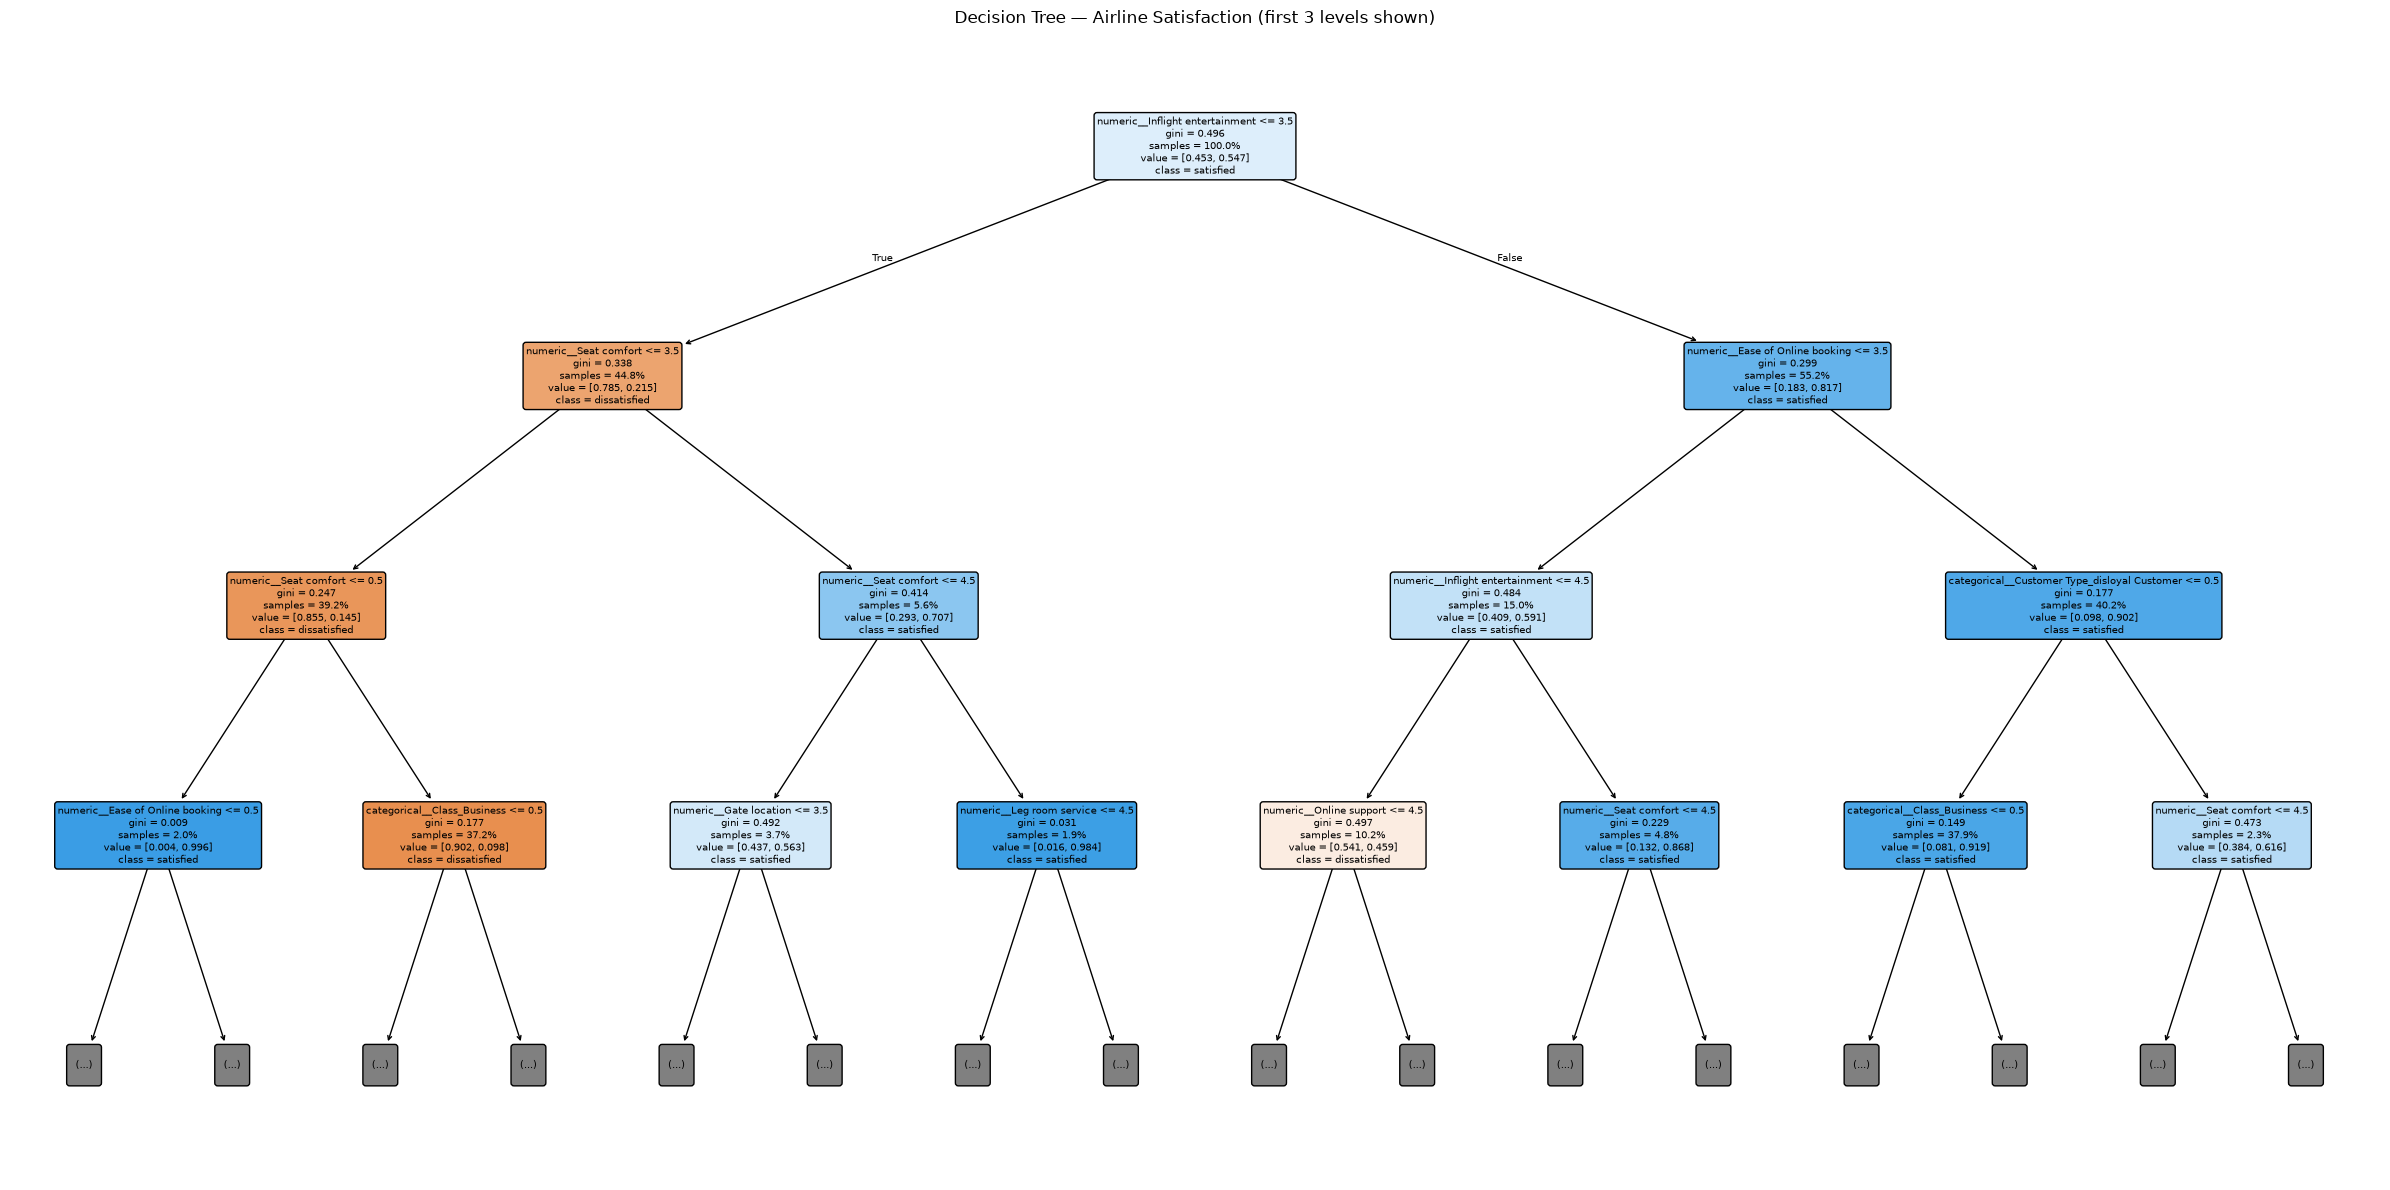

In [14]:
plt.figure(figsize=(24, 12))

plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=[str(label) for label in fitted_tree.classes_],
    filled=True,
    rounded=True,
    proportion=True,
    max_depth=3,
    fontsize=7,
)

plt.title("Decision Tree — Airline Satisfaction (first 3 levels shown)")
plt.tight_layout()

tree_path = OUTPUT_DIR / "decision_tree.png"
plt.savefig(tree_path, dpi=250, bbox_inches="tight")
plt.show()


## 11. Save and review project outputs

The notebook saves the same core artifacts as the Python script.


In [ ]:
print("Generated output files:")
for output_file in [
    tree_path,
    confusion_path,
    importance_path,
]:
    print(f"- {output_file.resolve()}")

print("\nNotebook workflow completed.")
print(f"All output files are saved in: {OUTPUT_DIR.resolve()}")
print("For educational purposes, you can open the generated decision tree image to visualize how the model makes predictions based on the features.")


Generated output files:
- C:\Users\Miguel Estrada\Desktop\Github\Python\decisiontree\decision_tree_output\decision_tree.png
- C:\Users\Miguel Estrada\Desktop\Github\Python\decisiontree\decision_tree_output\confusion_matrix.png
- C:\Users\Miguel Estrada\Desktop\Github\Python\decisiontree\decision_tree_output\feature_importances.csv

Notebook workflow completed.
All output files are saved in: C:\Users\Miguel Estrada\Desktop\Github\Python\decisiontree\decision_tree_output


## 12. Conclusions and next steps

After running all cells, use the test metrics and visualizations to assess the model.

Suggested next steps:
- Compare this Decision Tree with Random Forest and Gradient Boosting classifiers.
- Expand the hyperparameter search and evaluate additional tree settings.
- Investigate class-level precision and recall to understand which satisfaction class is more difficult to predict.
- Try permutation importance or SHAP for additional model interpretation.
- Save the fitted pipeline with `joblib` if you want to reuse it for predictions on new passenger records.

**Important:** Do not report performance values until the notebook has been executed with the dataset. The test set should remain separate from model selection and tuning.
